# Task 1 – Aufgabe 2: Zweidimensionale Funktionen

2.1 Datengenerierung · 2.2 FFNN vs. ICNN · 2.3 Sobolev-Training · 2.4 Hyperelastizität

In [54]:
%load_ext autoreload
%autoreload 2

import time
import importlib
from typing import Callable, Literal

import equinox as eqx
import jax
import jax.numpy as jnp
import klax
import numpy as np
from matplotlib import pyplot as plt


import tmlsm.models as tm
from tmlsm.data import f1, f2, grad_f2
# from tmlsm.models import ICNN, FFNN, Sobolev
from tmlsm.losses import MSE, SobolevMSE


importlib.reload(tm)
# importlib.reload(tl)
# importlib.reload(td)


key = jax.random.PRNGKey(0)   # feste Seed für reproduzierbare Ergebnisse
STEPS = 10_000

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Dimensionen

- **Ausgangsmodell (Sec. 1):** Ein- und Ausgang sind `"scalar"`, also Shape `()` → `()`. Über `jax.vmap` wird es auf Batches `(N,)` → `(N,)` angewendet.
- **2D-Eingang:** Ein einzelner Punkt hat Shape `(2,)`, ein Batch `(N, 2)`. Der Ausgang bleibt skalar, also `(N,)`.
- **Wo im Code?** Nur im **ersten Layer** (`in_features`) und im **letzten Layer** (`out_features`) von `klax.nn.Linear`. Die Breite der verdeckten Layer ist davon unabhängig.

## 2.1 Datengenerierung

$f_1(\mathbf x) = x^2 - y^2$ (Sattel, **nicht konvex**), $f_2(\mathbf x) = x^2 + 0.5\,y^2$ (konvex), $\partial f_2/\partial\mathbf x = (2x,\; y)^T$, auf $20\times 20$ äquidistanten Punkten in $[-4,4]^2$.

X: (400, 2)  f1: (400,)  f2: (400,)  grad f2: (400, 2)


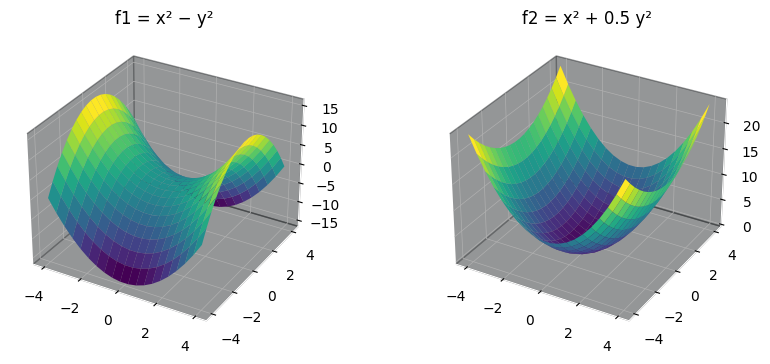

In [55]:


xs = np.linspace(-4.0, 4.0, 20)
XX, YY = np.meshgrid(xs, xs)
X = np.stack([XX.ravel(), YY.ravel()], axis=-1)   # (400, 2)
Y1, Y2, DY2 = f1(X), f2(X), grad_f2(X)
print("X:", X.shape, " f1:", Y1.shape, " f2:", Y2.shape, " grad f2:", DY2.shape)

fig = plt.figure(figsize=(10, 4))
for i, (Z, t) in enumerate([(Y1, "f1 = x² − y²"), (Y2, "f2 = x² + 0.5 y²")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(XX, YY, Z.reshape(XX.shape), cmap="viridis")
    ax.set_title(t)

# plt.savefig("images/functions.png",
#             facecolor='white',   # figure background
#             transparent=False)
plt.show()

In [56]:
key, *ks = jax.random.split(key, 9)
models_22, hists_22 = {}, {}
fig = plt.figure(figsize=(13, 8))
for row, (fname, Y) in enumerate([("f1", Y1), ("f2", Y2)]):
    # ax = fig.add_subplot(2, 3, 3 * row + 1, projection="3d")
    # ax.plot_surface(XX, YY, Y.reshape(XX.shape), cmap="viridis")
    # ax.set_title(f"{fname} (Daten)")
    for col, (name, cls) in enumerate([("FFNN", tm.FFNN), ("ICNN", tm.ICNN)]):
        i = 4 * row + 2 * col
        m, h = klax.fit(cls(in_features=2, key=ks[i]), (X, Y),
                        loss_fn=MSE(),
                        batch_size=32,
                        steps=STEPS,
                        key=ks[i + 1])
        m = klax.finalize(m)
        models_22[(fname, name)], hists_22[(fname, name)] = m, h
        Yp = np.asarray(jax.vmap(m)(X))
        mse = np.mean((Y - Yp) ** 2)
        print(f"{name} auf {fname}:  MSE = {mse:.2e}")
        # ax = fig.add_subplot(2, 3, 3 * row + 2 + col, projection="3d")
        # ax.plot_surface(XX, YY, Yp.reshape(XX.shape), cmap="viridis")
        # ax.set_title(f"{name} auf {fname}, MSE = {mse:.1e}", fontsize=9)
        #
        #
        # fig1, ax1 = plt.subplots(subplot_kw={"projection": "3d"})
        # ax1.plot_surface(XX, YY, Yp.reshape(XX.shape), cmap="viridis")
        # plt.show()


# plt.tight_layout(); plt.show()

Step: 0, Loss: 6.159e+01
Step: 100, Loss: 4.976e+01
Step: 200, Loss: 3.826e+01
Step: 300, Loss: 2.142e+01
Step: 400, Loss: 7.471e+00
Step: 500, Loss: 2.603e+00
Step: 600, Loss: 1.789e+00
Step: 700, Loss: 1.531e+00
Step: 800, Loss: 1.394e+00
Step: 900, Loss: 1.313e+00
Step: 1000, Loss: 1.244e+00
Step: 1100, Loss: 1.184e+00
Step: 1200, Loss: 1.132e+00
Step: 1300, Loss: 1.082e+00
Step: 1400, Loss: 1.056e+00
Step: 1500, Loss: 9.966e-01
Step: 1600, Loss: 9.530e-01
Step: 1700, Loss: 9.089e-01
Step: 1800, Loss: 8.787e-01
Step: 1900, Loss: 8.419e-01
Step: 2000, Loss: 8.105e-01
Step: 2100, Loss: 7.877e-01
Step: 2200, Loss: 7.766e-01
Step: 2300, Loss: 7.310e-01
Step: 2400, Loss: 7.100e-01
Step: 2500, Loss: 6.934e-01
Step: 2600, Loss: 6.619e-01
Step: 2700, Loss: 6.365e-01
Step: 2800, Loss: 6.136e-01
Step: 2900, Loss: 5.917e-01
Step: 3000, Loss: 5.842e-01
Step: 3100, Loss: 5.575e-01
Step: 3200, Loss: 5.326e-01
Step: 3300, Loss: 5.125e-01
Step: 3400, Loss: 5.210e-01
Step: 3500, Loss: 4.914e-01
Step

<Figure size 1300x800 with 0 Axes>

dict_keys([('f1', 'FFNN'), ('f1', 'ICNN'), ('f2', 'FFNN'), ('f2', 'ICNN')])


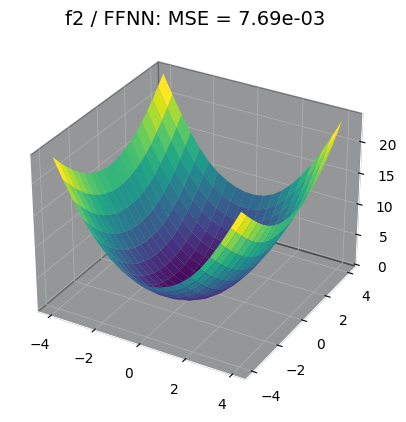

In [70]:
# plotting of model approximations
print(models_22.keys())

function ="f2"
model = "FFNN"

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
Z = np.asarray(jax.vmap(models_22[function, model])(X))
cmap = "viridis"
mse = np.mean((Y2 - Z) ** 2)

surf = ax.plot_surface(XX, YY, Z.reshape(XX.shape), cmap=cmap)
ax.set_title(f"{function} / {model}: MSE = {mse:.2e}", fontsize=14)
plt.savefig(f"images/{function}_{model}.svg",
            facecolor='white',   # figure background
            transparent=False)
plt.show()

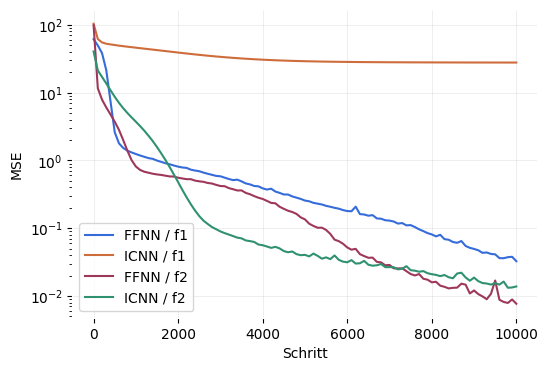

In [58]:
# Verlauf der Kalibrierung
plt.figure(figsize=(6, 4))
for (fname, name), h in hists_22.items():
    plt.semilogy(h.steps, h.loss, label=f"{name} / {fname}")
plt.xlabel("Schritt"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Beobachtung:**
- **f₁** ist eine Sattelfläche. Das FFNN approximiert sie sehr gut. Das ICNN kann sie **per Konstruktion nicht darstellen**: Es liefert die bestmögliche *konvexe* Näherung (eine Art Rinne in x-Richtung), der Fehler bleibt groß.
- **f₂** ist konvex, beide Netze treffen sie. Beim ICNN ist Konvexität aber *garantiert*, auch zwischen und außerhalb der Datenpunkte.

## 2.3 Sobolev-Training

Ein **Differential-Layer** liefert beide Ausgänge:

$$\text{Output}_1 = \text{ICNN}(\mathbf x;\mathbf p)\in\mathbb R,\qquad \text{Output}_2 = \frac{\partial\,\text{ICNN}(\mathbf x;\mathbf p)}{\partial\mathbf x}\in\mathbb R^2$$

Die Ableitung kommt aus `jax.grad` (hier `jax.value_and_grad`, das gibt beides in einem Aufruf).
Der Loss $w_f\,\text{MSE}(f) + w_g\,\text{MSE}(\nabla f)$ deckt mit passenden Gewichten alle drei Strategien ab.

In [59]:
strategies = {"nur f2": (1.0, 0.0), "f2 + Gradient": (1.0, 1.0), "nur Gradient": (0.0, 1.0)}
key, *ks = jax.random.split(key, 7)

models_sobolev, hists_sobolev = {}, {}
# fig, axes = plt.subplots(3, 4, figsize=(16, 11))
y0 = np.isclose(X[:, 1], X[np.argmin(np.abs(X[:, 1])), 1])  # Schnitt y ≈ 0

for i, (name, (wf, wg)) in enumerate(strategies.items()):
    m, h = klax.fit(tm.Sobolev(tm.ICNN(in_features=2, key=ks[2 * i])),
                    (X, (Y2, DY2)),
                    batch_size=32,
                    steps=STEPS,
                    loss_fn=SobolevMSE(wf, wg),
                    key= ks[2 * i + 1])
    m = klax.finalize(m)
    models_sobolev[name], hists_sobolev[name] = m, h

    yp, dyp = map(np.asarray, jax.vmap(m)(X))
    print(f"{name:15s}  MSE f2 = {np.mean((Y2 - yp)**2):.2e}   "
          f"MSE grad = {np.mean((DY2 - dyp)**2):.2e}")
#     for j, (true, pred, lab) in enumerate([(Y2, yp, "f2"), (DY2[:, 0], dyp[:, 0], "∂f2/∂x"),
#                                            (DY2[:, 1], dyp[:, 1], "∂f2/∂y")]):
#
#         ax = fig.add_subplot(2, 3, 3 * row + 2 + col, projection="3d")
#         ax.plot_surface(XX, YY, Yp.reshape(XX.shape), cmap="viridis")
#
#         ax = axes[i, j]
#         cs = ax.contourf(XX, YY, pred.reshape(XX.shape), 20, cmap="viridis")
#         ax.contour(XX, YY, true.reshape(XX.shape), 10, colors="k", linewidths=0.6, linestyles="--")
#         fig.colorbar(cs, ax=ax)
#         ax.set_title(f"{name}: {lab}  (Farbe = NN, -- = exakt)", fontsize=8)
#     ax = axes[i, 3]
#     ax.plot(X[y0, 0], Y2[y0], "k--", label="f2 exakt")
#     ax.plot(X[y0, 0], yp[y0], "r", label="NN")
#     ax.set_title(f"{name}: Schnitt y ≈ 0", fontsize=8); ax.legend(fontsize=7)
# plt.tight_layout(); plt.show()

Step: 0, Loss: 2.527e+01
Step: 100, Loss: 1.107e+01
Step: 200, Loss: 8.895e+00
Step: 300, Loss: 7.372e+00
Step: 400, Loss: 6.278e+00
Step: 500, Loss: 5.460e+00
Step: 600, Loss: 4.763e+00
Step: 700, Loss: 4.153e+00
Step: 800, Loss: 3.590e+00
Step: 900, Loss: 3.072e+00
Step: 1000, Loss: 2.595e+00
Step: 1100, Loss: 2.164e+00
Step: 1200, Loss: 1.786e+00
Step: 1300, Loss: 1.452e+00
Step: 1400, Loss: 1.175e+00
Step: 1500, Loss: 9.466e-01
Step: 1600, Loss: 7.573e-01
Step: 1700, Loss: 6.124e-01
Step: 1800, Loss: 5.026e-01
Step: 1900, Loss: 4.212e-01
Step: 2000, Loss: 3.596e-01
Step: 2100, Loss: 3.114e-01
Step: 2200, Loss: 2.794e-01
Step: 2300, Loss: 2.572e-01
Step: 2400, Loss: 2.314e-01
Step: 2500, Loss: 2.142e-01
Step: 2600, Loss: 2.001e-01
Step: 2700, Loss: 1.874e-01
Step: 2800, Loss: 1.763e-01
Step: 2900, Loss: 1.672e-01
Step: 3000, Loss: 1.559e-01
Step: 3100, Loss: 1.458e-01
Step: 3200, Loss: 1.364e-01
Step: 3300, Loss: 1.297e-01
Step: 3400, Loss: 1.210e-01
Step: 3500, Loss: 1.143e-01
Step

dict_keys(['nur f2', 'f2 + Gradient', 'nur Gradient'])


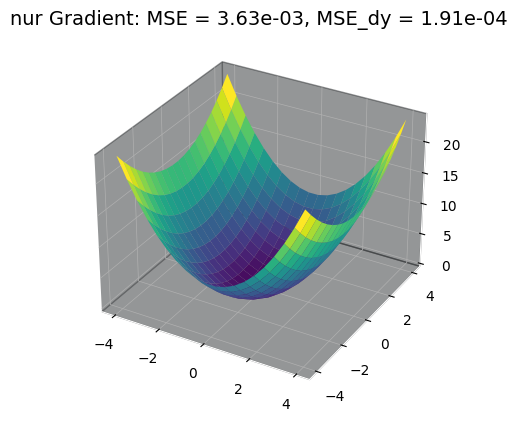

In [60]:
# Plotting area
print(models_sobolev.keys())

strategy = "nur Gradient" #"nur f2" "f2 + Gradient""nur Gradient"


fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
yp, dyp = map(np.asarray, jax.vmap(models_sobolev[strategy])(X))

cmap = "viridis"
mse = np.mean((Y2 - (yp - min(yp))) ** 2)
mse_dy = np.mean((DY2 - dyp) ** 2)

yy = (yp - min(yp))

surf = ax.plot_surface(XX, YY, yy.reshape(XX.shape), cmap=cmap)
ax.set_title(f"{strategy}: MSE = {mse:.2e}, MSE_dy = {mse_dy:.2e}", fontsize=14)
# plt.savefig(f"images/Sobolev_f2_grad_f2.svg",
#             facecolor='white',   # figure background
#             transparent=False)
plt.show()

**Beobachtung:**
- **Nur f₂:** Die Funktion passt, der Gradient wird nur indirekt mitgelernt und ist etwas ungenauer.
- **f₂ + Gradient:** Beide passen, der Gradient deutlich besser. Die Ableitungsdaten wirken als zusätzliche Information bzw. Regularisierung.
- **Nur Gradient:** Der Gradient passt am besten, aber **f₂ ist um eine Konstante verschoben** (siehe Schnitt). Ein Gradient bestimmt die Funktion nur bis auf eine additive Konstante. Genau das ist bei der Hyperelastizität relevant: Gemessen wird die Spannung, nicht die Energie. Die Konstante legt man dort über eine Normierung fest, z. B. $W(0)=0$.

## 2.4 Hyperelastizität (1D)

Potential $W = \text{NN}(\varepsilon)$, Spannung $\sigma^{NN} = \partial\,\text{NN}(\varepsilon)/\partial\varepsilon$. Kalibriert wird **nur auf σ** ($w_f=0$), weil die Energie nicht gemessen ist.

> **Eigenen Gruppendatensatz einsetzen:** unten `DATA_PATH` setzen. Erwartet werden zwei Spalten (ε, σ); `delimiter`/`skiprows` ggf. anpassen. Ohne Pfad laufen synthetische Platzhalterdaten.

In [61]:
DATA_PATH = "data_hyper.txt"  # z.B. "data/gruppe_XY.txt"

def load_hyperelastic(path=None):
    if path is not None:
        d = np.loadtxt(path, delimiter=None, skiprows=0)
        return d[:, 0], d[:, 1]
    raise ValueError("DATA_PATH not set")
    # eps = np.linspace(0.01, 2.0, 60)                      # Platzhalter: versteifendes Polymer
    # sig = 0.8 * eps + 0.15 * eps**3
    # return eps, sig + 0.02 * np.random.default_rng(0).standard_normal(eps.shape)

eps, sig = load_hyperelastic(DATA_PATH)

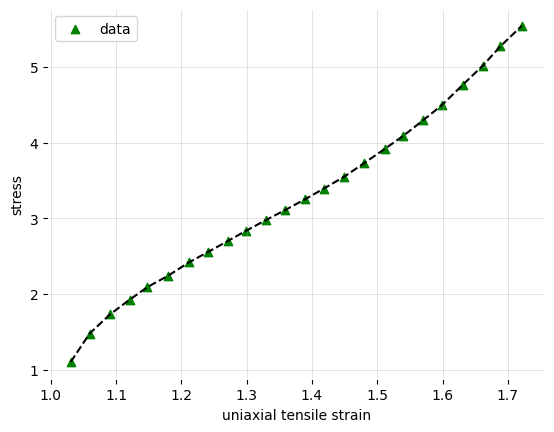

In [62]:
# plot data
fig, ax = plt.subplots()
ax.plot(eps, sig, color="black", ls="--")
ax.scatter(eps, sig, color="green", marker="^", label="data")
ax.set_xlabel("uniaxial tensile strain") #eps
ax.set_ylabel("stress") #sigma
ax.grid()
ax.legend()
plt.show()

In [109]:
# Interpolation:
STEPS = 50000
key, *ks = jax.random.split(key, 5)

models_hyper, hists_hyper = {}, {}
for i, (name, cls, color) in enumerate([("FFNN", tm.FFNN, "red"), ("ICNN", tm.ICNN, "blue")]):
    m, h = klax.fit(tm.Sobolev(cls(in_features="scalar", key=ks[2 * i])),
               (eps, (np.zeros_like(eps), sig)),   # W-Daten egal, da w_f = 0
                    batch_size=16,
                    steps=STEPS,
                    loss_fn=SobolevMSE(w_f=0.0, w_g=1.0),
                    key=ks[2 * i + 1])
    m = klax.finalize(m)
    models_hyper[name], hists_hyper[name] = m, h

    # evaluate model at evaluation points:
    W, dW = map(np.asarray, jax.vmap(m)(eps))

    # Normalization W(0) = 0:
    W = W- m(jnp.asarray(0.0))[0]

    mse_dW = np.mean((dW - sig)**2)

    print(f"{name}:  MSE Interpolation (grad) = {mse_dW:.2e}")


Step: 0, Loss: 2.551e+00
Step: 100, Loss: 9.352e-01
Step: 200, Loss: 4.343e-01
Step: 300, Loss: 9.983e-02
Step: 400, Loss: 4.455e-02
Step: 500, Loss: 3.657e-02
Step: 600, Loss: 3.284e-02
Step: 700, Loss: 2.884e-02
Step: 800, Loss: 2.759e-02
Step: 900, Loss: 2.467e-02
Step: 1000, Loss: 2.444e-02
Step: 1100, Loss: 2.276e-02
Step: 1200, Loss: 2.111e-02
Step: 1300, Loss: 1.979e-02
Step: 1400, Loss: 1.903e-02
Step: 1500, Loss: 1.947e-02
Step: 1600, Loss: 1.744e-02
Step: 1700, Loss: 1.666e-02
Step: 1800, Loss: 1.625e-02
Step: 1900, Loss: 1.646e-02
Step: 2000, Loss: 1.545e-02
Step: 2100, Loss: 1.487e-02
Step: 2200, Loss: 1.468e-02
Step: 2300, Loss: 1.376e-02
Step: 2400, Loss: 1.502e-02
Step: 2500, Loss: 1.372e-02
Step: 2600, Loss: 1.300e-02
Step: 2700, Loss: 1.275e-02
Step: 2800, Loss: 1.258e-02
Step: 2900, Loss: 1.231e-02
Step: 3000, Loss: 1.215e-02
Step: 3100, Loss: 1.253e-02
Step: 3200, Loss: 1.242e-02
Step: 3300, Loss: 1.174e-02
Step: 3400, Loss: 1.163e-02
Step: 3500, Loss: 1.158e-02
Step

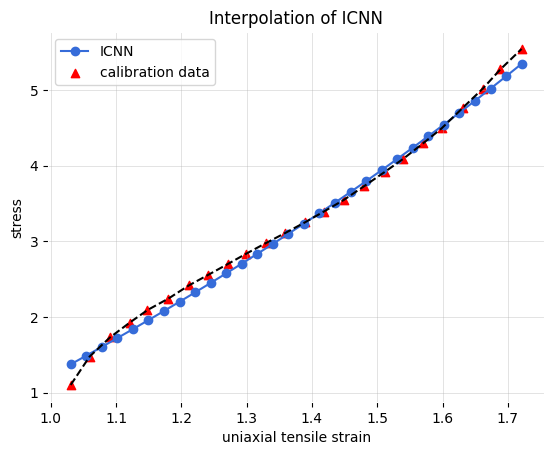

In [111]:
# plotting of interpolation

fig, ax = plt.subplots()

model = "ICNN"

# model evaluation points
x = np.linspace(eps.min(), eps.max(), 30)
W, dW = map(np.asarray, jax.vmap(models_hyper[model])(x))

# ax.scatter(x, dW, color="red", label=f"{model}", marker="x")
ax.plot(x, dW, label=f"{model}", ls="-", marker="o")

ax.plot(eps, sig, color="black", ls="--")
ax.scatter(eps, sig, color="red", marker="^", label="calibration data")
ax.set_xlabel("uniaxial tensile strain") #eps
ax.set_ylabel("stress") #sigma
ax.set_title(f"Interpolation of {model}")
ax.grid()
ax.legend()
plt.show()

In [106]:
# Extrapolation:

key, *ks = jax.random.split(key, 5)

idx = np.searchsorted(eps, 1.3)

eps_train = eps[0:idx]
sig_train = sig[0:idx]


models_hyper_ex, hists_hyper_ex = {}, {}
for i, (name, cls, color) in enumerate([("FFNN", tm.FFNN, "red"), ("ICNN", tm.ICNN, "blue")]):
    m, h = klax.fit(tm.Sobolev(cls(in_features="scalar", key=ks[2 * i])),
               (eps_train, (np.zeros_like(eps_train), sig_train)),   # W-Daten egal, da w_f = 0
                    batch_size=16,
                    steps=STEPS,
                    loss_fn=SobolevMSE(w_f=0.0, w_g=1.0),
                    key=ks[2 * i + 1])
    m = klax.finalize(m)
    models_hyper_ex[name], hists_hyper_ex[name] = m, h

    # evaluate model at evaluation points:
    W, dW = map(np.asarray, jax.vmap(m)(eps))

    # Normalization W(0) = 0:
    W = W- m(jnp.asarray(0.0))[0]

    mse_dW = np.mean((dW - sig)**2)

    print(f"{name}:  MSE Extrapolation (grad) = {mse_dW:.2e}")


Step: 0, Loss: 2.070e+01
Step: 100, Loss: 2.751e-01
Step: 200, Loss: 2.636e-01
Step: 300, Loss: 2.515e-01
Step: 400, Loss: 2.397e-01
Step: 500, Loss: 2.291e-01
Step: 600, Loss: 2.192e-01
Step: 700, Loss: 2.094e-01
Step: 800, Loss: 1.994e-01
Step: 900, Loss: 1.885e-01
Step: 1000, Loss: 1.762e-01
Step: 1100, Loss: 1.615e-01
Step: 1200, Loss: 1.421e-01
Step: 1300, Loss: 1.140e-01
Step: 1400, Loss: 7.234e-02
Step: 1500, Loss: 2.597e-02
Step: 1600, Loss: 5.620e-03
Step: 1700, Loss: 3.389e-03
Step: 1800, Loss: 3.097e-03
Step: 1900, Loss: 2.875e-03
Step: 2000, Loss: 2.684e-03
Step: 2100, Loss: 2.518e-03
Step: 2200, Loss: 2.373e-03
Step: 2300, Loss: 2.244e-03
Step: 2400, Loss: 2.129e-03
Step: 2500, Loss: 2.025e-03
Step: 2600, Loss: 1.931e-03
Step: 2700, Loss: 1.846e-03
Step: 2800, Loss: 1.767e-03
Step: 2900, Loss: 1.695e-03
Step: 3000, Loss: 1.628e-03
Step: 3100, Loss: 1.567e-03
Step: 3200, Loss: 1.510e-03
Step: 3300, Loss: 1.458e-03
Step: 3400, Loss: 1.410e-03
Step: 3500, Loss: 1.366e-03
Step

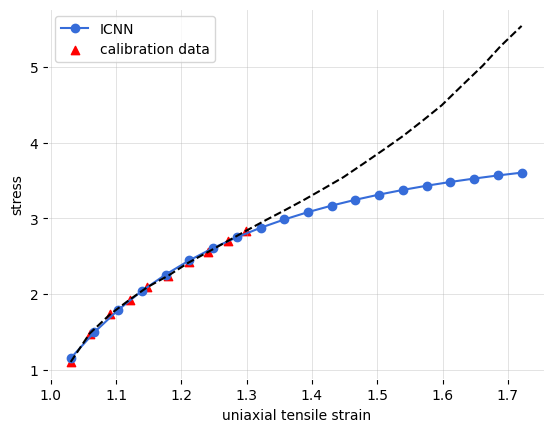

In [107]:
# plotting of interpolation

fig, ax = plt.subplots()

model = "ICNN"

# model evaluation points
x = np.linspace(eps.min(), eps.max(), 20)
W, dW = map(np.asarray, jax.vmap(models_hyper_ex[model])(x))

# ax.scatter(x, dW, color="red", label=f"{model}", marker="x")
ax.plot(x, dW, label=f"{model}", ls="-", marker="o")

ax.plot(eps, sig, color="black", ls="--")
ax.scatter(eps_train, sig_train, color="red", marker="^", label="calibration data")
ax.set_xlabel("uniaxial tensile strain") #eps
ax.set_ylabel("stress") #sigma
ax.set_title(f"Extrapolation of {model}")
ax.grid()
ax.legend()
plt.show()

**Diskussion:**
- **Interpolation:** Beide Modelle treffen die Kalibrierdaten gut.
- **FFNN:** Nichts garantiert hier ein konvexes $W$. Außerhalb der Daten kann die Spannung beliebig verlaufen, auch fallen (unphysikalisch, vgl. Folie „NN models: flexible but not physical“).
- **ICNN:** $W$ ist garantiert konvex, die Spannung $\sigma=W'$ also **monoton steigend**. Das ist eine *Garantie* für physikalisch plausibles Verhalten, aber nicht automatisch ein kleinerer Extrapolationsfehler: Im Lauf hier (feste Seed) liegt das FFNN auf den Testdaten sogar näher dran. Bei anderen Seeds kann das FFNN dagegen abknicken oder fallen, das ICNN nie. Am besten mehrere Seeds vergleichen.
- **Aber:** Mit Softplus ist $\sigma$ eine Summe von Sigmoid-artigen Termen und **sättigt** für große ε. Konvexität verhindert das Abfallen, nicht das Abflachen. Ein versteifendes Material wird deshalb trotzdem unterschätzt. Physikalisches Wissen (Wachstumsbedingungen, Korrekturterme) muss dafür zusätzlich eingebaut werden, das ist Thema der PANN-Modelle in Task 2.